# **S6 Churn Prediction**

This stage defines a churn outcome from respondents' current playing status, prepares respondent and game-related predictors, and compares Logistic Regression with Random Forest. It evaluates model performance with stratified cross-validation and summarizes out-of-fold predictions.

In [2]:
from pathlib import Path
import pandas as pd

# Resolve the project root whether the notebook runs from the project or analysis folder.
project_root = Path.cwd()
if not (project_root / "Dataset").exists() and (project_root.parent / "Dataset").exists():
    project_root = project_root.parent

output_dir = project_root / "outputs" / "stage6"
figures_dir = output_dir / "figures"
tables_dir = output_dir / "tables"
figures_dir.mkdir(parents=True, exist_ok=True)
tables_dir.mkdir(parents=True, exist_ok=True)

candidates = [
    project_root / "Dataset" / "gacha_clean.csv",
    project_root / "Satisfaction" / "gacha_clean.csv",
    project_root / "gacha_clean.csv",
]
csv_path = next((path for path in candidates if path.exists()), None)
assert csv_path is not None, "Could not find gacha_clean.csv in the expected data locations"

df = pd.read_csv(csv_path, encoding="utf-8-sig")
print("File:", csv_path)
print("Shape:", df.shape)
print(df["STATUS"].value_counts())

File: ..\Dataset\gacha_clean.csv
Shape: (510, 52)
STATUS
Active, playing as usual         382
Playing much less than before    111
Quit in the last 6 months         17
Name: count, dtype: int64


## **S6.1 Define the Churn Outcome**

`CHURN = 0` represents respondents who are still playing as usual. `CHURN = 1` combines respondents who are playing much less and those who quit within the last six months.

The target contains 382 non-churn and 128 churn observations out of 510 respondents, so the churn rate is 25.1%.

In [3]:
status_to_churn = {
    "Active, playing as usual": 0,
    "Playing much less than before": 1,
    "Quit in the last 6 months": 1,
}

df["CHURN"] = df["STATUS"].map(status_to_churn)

assert df["CHURN"].notna().all(), "Some STATUS values are not mapped"
df["CHURN"] = df["CHURN"].astype(int)

print(df["CHURN"].value_counts().sort_index())
print("CHURN = 1 rate:", f"{df['CHURN'].mean():.1%}")

CHURN
0    382
1    128
Name: count, dtype: int64
CHURN = 1 rate: 25.1%


## **Prepare the Predictors**

The predictors include age, game, playing tenure, monthly spending group, promotion use, luck, pity fairness, price fairness, and satisfaction. Categorical variables are one-hot encoded; numeric variables are standardized.

`STATUS` is excluded from the predictors because it is used to define the churn outcome.

In [4]:
categorical_features = [
    "AGE",
    "GAME",
    "TENURE",
    "SPEND_MONTH4",
    "PROMO",
]

numeric_features = [
    "LUCK",
    "PITY2",
    "PRICE",
    "SAT",
]

feature_columns = categorical_features + numeric_features
X = df[feature_columns].copy()
y = df["CHURN"].copy()

assert X.notna().all().all(), "Input features contain missing values"
assert len(X) == len(y) == 510

print("Input features:", feature_columns)
print("X shape:", X.shape)
print("Target distribution:", y.value_counts().sort_index().to_dict())

Input features: ['AGE', 'GAME', 'TENURE', 'SPEND_MONTH4', 'PROMO', 'LUCK', 'PITY2', 'PRICE', 'SAT']
X shape: (510, 9)
Target distribution: {0: 382, 1: 128}


In [4]:
%pip install scikit-learn

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   ------- -------------------------------- 1.6/8.4 MB 10.6 MB/s eta 0:00:01
   ------------------ --------------------- 3.9/8.4 MB 11.4 MB/s eta 0:00:01
   ------------------------- -------------- 5.2/8.4 MB 9.2 MB/s eta 0:00:01
   ------------------------------------ --- 7.6/8.4 MB 9.9 MB/s eta 0:00:01
   ---------------------------------------- 8.4/8.4 MB 9.6 MB/s  0:00:00

   -------------------- ------------------- 2/4 [joblib]
   -------------------- ------------------- 2/4 [joblib]
   -------------------- ------------------- 2/4 [joblib]
   -------------------- ------------------- 2/4 [joblib]
   -------------------- ------------------- 2/4 [joblib]
   -------------------- ------------------- 2/4 [joblib]
   ------------------------------ --------- 3/4 [scikit-learn]
   ------------------------------ --------- 3/4 [scikit-learn]
   --

## **S6.2 Classification Models**

The analysis compares Logistic Regression and Random Forest. Both pipelines use balanced class weights to account for the smaller churn group. The same preprocessing steps are applied inside each pipeline.

In [5]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

preprocess = ColumnTransformer(
    transformers=[
        ("categorical", OneHotEncoder(handle_unknown="ignore"),
         categorical_features),
        ("numeric", StandardScaler(), numeric_features),
    ]
)

models = {
    "Logistic Regression": Pipeline([
        ("preprocess", preprocess),
        ("model", LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
        )),
    ]),
    "Random Forest": Pipeline([
        ("preprocess", preprocess),
        ("model", RandomForestClassifier(
            n_estimators=300,
            min_samples_leaf=5,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1,
        )),
    ]),
}

print(list(models))

['Logistic Regression', 'Random Forest']


## **Compare Models with Stratified 5-Fold Cross-Validation**

Stratified folds preserve the churn / non-churn proportions in each split. ROC-AUC, F1, precision, and recall are reported as the mean and standard deviation across five folds.

In [6]:
import pandas as pd
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42,
)

scoring = {
    "ROC-AUC": "roc_auc",
    "F1": "f1",
    "Precision": "precision",
    "Recall": "recall",
}

rows = []

for name, model in models.items():
    scores = cross_validate(
        model,
        X,
        y,
        cv=cv,
        scoring=scoring,
        error_score="raise",
    )

    row = {"Model": name}
    for metric in scoring:
        fold_values = scores[f"test_{metric}"]
        row[f"{metric} mean"] = fold_values.mean()
        row[f"{metric} SD"] = fold_values.std(ddof=1)
    rows.append(row)

s6_model_comparison = pd.DataFrame(rows)
s6_model_comparison.to_csv(
    tables_dir / "cross_validation_model_comparison.csv",
    index=False,
    encoding="utf-8-sig",
)
display(s6_model_comparison.round(3))


,Model,ROC-AUC mean,ROC-AUC SD,F1 mean,F1 SD,Precision mean,Precision SD,Recall mean,Recall SD
0,Logistic Regression,0.687,0.045,0.460,0.076,0.371,0.053,0.610,0.128
1,Random Forest,0.688,0.041,0.468,0.055,0.411,0.035,0.548,0.101


### **Cross-Validation Results**

The models have nearly identical mean ROC-AUC values: 0.687 for Logistic Regression and 0.688 for Random Forest. Random Forest has a slightly higher mean F1 score (0.468 vs. 0.460) and precision (0.411 vs. 0.371), while Logistic Regression has higher recall (0.610 vs. 0.548). The results show a trade-off rather than a clear overall winner.

## **S6.3 Out-of-Fold Evaluation**

Each respondent receives a prediction from a model that did not train on that respondent's row. The following metrics summarize the combined out-of-fold predictions at a probability threshold of 0.5.

In [8]:
import numpy as np
import pandas as pd

from sklearn.model_selection import cross_val_predict
from sklearn.metrics import (
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)

oof_results = []
predictions = {}

for name, model in models.items():
    # Each respondent is predicted by a model that was not trained on their row.
    probability = cross_val_predict(
        model, X, y, cv=cv, method="predict_proba"
    )[:, 1]

    predicted = (probability >= 0.5).astype(int)
    predictions[name] = {
        "probability": probability,
        "predicted": predicted,
    }

    tn, fp, fn, tp = confusion_matrix(
        y, predicted, labels=[0, 1]
    ).ravel()

    oof_results.append({
        "Model": name,
        "ROC-AUC": roc_auc_score(y, probability),
        "F1": f1_score(y, predicted),
        "Precision": precision_score(y, predicted, zero_division=0),
        "Recall": recall_score(y, predicted, zero_division=0),
        "TN": tn, "FP": fp, "FN": fn, "TP": tp,
    })

oof_table = pd.DataFrame(oof_results)
display(oof_table.round(3))

oof_table.to_csv(
    tables_dir / "model_metrics_oof.csv",
    index=False,
    encoding="utf-8-sig",
)

,Model,ROC-AUC,F1,Precision,Recall,TN,FP,FN,TP
0,Logistic Regression,0.684,0.463,0.373,0.609,251,131,50,78
1,Random Forest,0.683,0.470,0.412,0.547,282,100,58,70


### **Out-of-Fold Confusion Matrices**

The confusion matrices show different error trade-offs. Logistic Regression identifies more churn cases (78 true positives vs. 70 for Random Forest) but also produces more false positives (131 vs. 100). Random Forest labels fewer non-churn respondents as churn, while missing more churn cases (58 false negatives vs. 50).

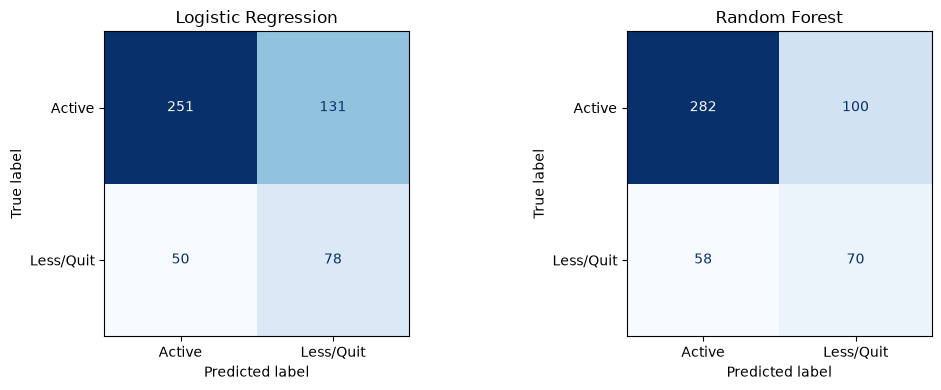

In [9]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, (name, result) in zip(axes, predictions.items()):
    ConfusionMatrixDisplay.from_predictions(
        y,
        result["predicted"],
        labels=[0, 1],
        display_labels=["Active", "Less/Quit"],
        cmap="Blues",
        colorbar=False,
        ax=ax,
    )
    ax.set_title(name)

fig.tight_layout()
fig.savefig(figures_dir / "confusion_matrices.png", dpi=180)
plt.show()

### **Out-of-Fold ROC Curves**

Both models achieve ROC-AUC values near 0.68, above the random-ranking reference but indicating modest separation between churn and non-churn respondents. Their curves are very similar.

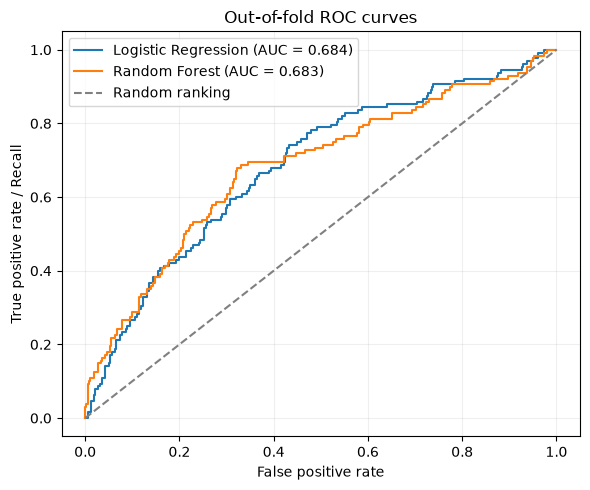

In [10]:
from sklearn.metrics import roc_curve

fig, ax = plt.subplots(figsize=(6, 5))

for name, result in predictions.items():
    fpr, tpr, _ = roc_curve(y, result["probability"])
    auc_value = roc_auc_score(y, result["probability"])
    ax.plot(fpr, tpr, label=f"{name} (AUC = {auc_value:.3f})")

ax.plot([0, 1], [0, 1], "--", color="gray", label="Random ranking")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate / Recall")
ax.set_title("Out-of-fold ROC curves")
ax.legend()
ax.grid(alpha=0.2)

fig.tight_layout()
fig.savefig(figures_dir / "roc_curves.png", dpi=180)
plt.show()

## **Random Forest Permutation Importance**

Permutation importance measures how much validation ROC-AUC changes when a feature is shuffled. Satisfaction (`SAT`) has the largest mean AUC decrease (0.148), followed by monthly spending group (0.027), promotion use (0.018), and price fairness (0.014). The remaining features have small or slightly negative average values, so their importance is less clear in this sample.

These values describe predictive usefulness in this model; they do not show that a feature causes churn.

,Feature,Mean AUC decrease,SD across folds
8,SAT,0.148,0.032
3,SPEND_MONTH4,0.027,0.009
4,PROMO,0.018,0.009
7,PRICE,0.014,0.005
1,GAME,0.012,0.018
5,LUCK,0.012,0.012
2,TENURE,0.004,0.025
0,AGE,-0.006,0.003
6,PITY2,-0.013,0.017


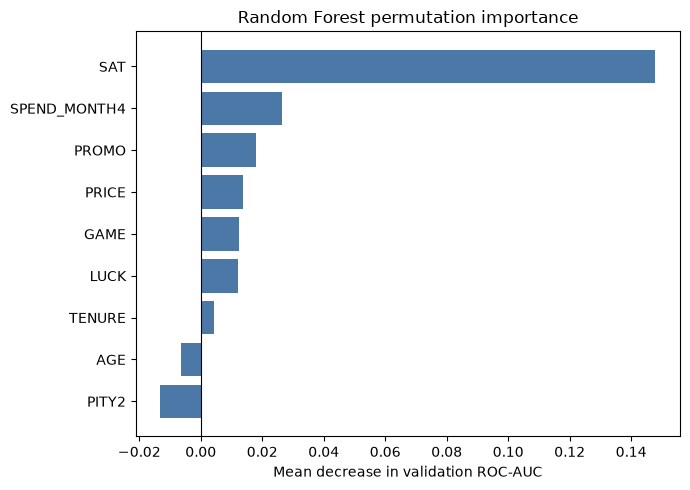

In [11]:
from sklearn.base import clone
from sklearn.inspection import permutation_importance

fold_importances = []

for train_idx, test_idx in cv.split(X, y):
    fitted = clone(models["Random Forest"])
    fitted.fit(X.iloc[train_idx], y.iloc[train_idx])

    result = permutation_importance(
        fitted,
        X.iloc[test_idx],
        y.iloc[test_idx],
        scoring="roc_auc",
        n_repeats=5,
        random_state=42,
        n_jobs=1,
    )
    fold_importances.append(result.importances_mean)

importance_table = pd.DataFrame({
    "Feature": X.columns,
    "Mean AUC decrease": np.mean(fold_importances, axis=0),
    "SD across folds": np.std(fold_importances, axis=0, ddof=1),
}).sort_values("Mean AUC decrease", ascending=False)

display(importance_table.round(3))
importance_table.to_csv(
    tables_dir / "permutation_importance.csv",
    index=False,
    encoding="utf-8-sig",
)

plot_data = importance_table.sort_values("Mean AUC decrease")
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(
    plot_data["Feature"],
    plot_data["Mean AUC decrease"],
    color="#4C78A8",
)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Mean decrease in validation ROC-AUC")
ax.set_title("Random Forest permutation importance")
fig.tight_layout()
fig.savefig(figures_dir / "permutation_importance.png", dpi=180)
plt.show()

### **Summary**

The two models produce similar, modest ROC-AUC results. Random Forest has slightly higher F1 in the pooled out-of-fold results, while Logistic Regression has higher recall. Satisfaction is the strongest permutation-importance signal. Treat these findings as exploratory associations from a sample of 510 respondents, not as causal effects or a standalone basis for decisions.